In [ ]:
import pandas as pd

col_names = ["timestamp", "can_id", "dlc",
             "d0", "d1", "d2", "d3", "d4", "d5", "d6", "d7", "flag"]

df = pd.read_csv("9) Car-Hacking Dataset/DoS_dataset.csv", names=col_names, header=None)
print(df.shape)
df.head(10)

(3665771, 12)


,timestamp,can_id,dlc,d0,d1,d2,d3,d4,d5,d6,d7,flag
0,1.478198e+09,0316,8,05,21,68,09,21,21,00,6f,R
1,1.478198e+09,018f,8,fe,5b,00,00,00,3c,00,00,R
2,1.478198e+09,0260,8,19,21,22,30,08,8e,6d,3a,R
3,1.478198e+09,02a0,8,64,00,9a,1d,97,02,bd,00,R
4,1.478198e+09,0329,8,40,bb,7f,14,11,20,00,14,R
5,1.478198e+09,0545,8,d8,00,00,8a,00,00,00,00,R
6,1.478198e+09,0002,8,00,00,00,00,00,03,0b,11,R
7,1.478198e+09,0153,8,00,21,10,ff,00,ff,00,00,R
8,1.478198e+09,02c0,8,14,00,00,00,00,00,00,00,R
9,1.478198e+09,0130,8,08,80,00,ff,31,80,0b,7f,R


In [3]:
df["flag"].value_counts()


flag
R    3047062
T     587521
Name: count, dtype: int64

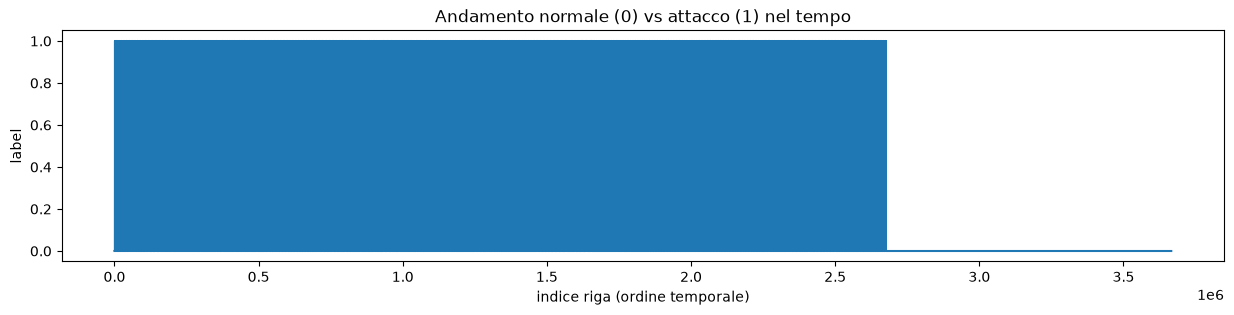

In [ ]:
import matplotlib.pyplot as plt

df["label"] = (df["flag"] == "T").astype(int)

plt.figure(figsize=(15, 3))
plt.plot(df["label"].values)
plt.title("Andamento normale (0) vs attacco (1) nel tempo")
plt.xlabel("indice riga (ordine temporale)")
plt.ylabel("label")
plt.show()

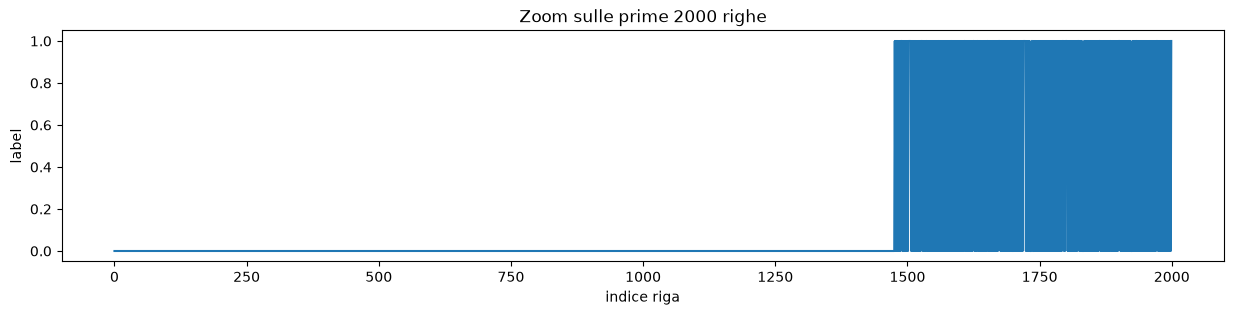

In [5]:
plt.figure(figsize=(15, 3))
plt.plot(df["label"].values[:2000])
plt.title("Zoom sulle prime 2000 righe")
plt.xlabel("indice riga")
plt.ylabel("label")
plt.show()

In [ ]:
df = df.sort_values("timestamp").reset_index(drop=True)

df["iat"] = df.groupby("can_id")["timestamp"].diff()

df[["timestamp", "can_id", "iat", "label"]].head(15)

,timestamp,can_id,iat,label
0,1.478198e+09,0316,NaN,0
1,1.478198e+09,018f,NaN,0
2,1.478198e+09,0260,NaN,0
3,1.478198e+09,02a0,NaN,0
4,1.478198e+09,0329,NaN,0
5,1.478198e+09,0545,NaN,0
6,1.478198e+09,0002,NaN,0
7,1.478198e+09,0153,NaN,0
8,1.478198e+09,02c0,NaN,0
9,1.478198e+09,0130,NaN,0


In [7]:
df[["timestamp", "can_id", "iat", "label"]].iloc[100:115]

,timestamp,can_id,iat,label
100,1.478198e+09,04b1,0.019987,0
101,1.478198e+09,01f1,0.019987,0
102,1.478198e+09,0153,0.010490,0
103,1.478198e+09,0002,0.010968,0
104,1.478198e+09,02c0,0.010378,0
105,1.478198e+09,0350,0.010040,0
106,1.478198e+09,0130,0.011124,0
107,1.478198e+09,0131,0.011124,0
108,1.478198e+09,0140,0.011121,0
109,1.478198e+09,0370,0.010055,0


In [8]:
df[["timestamp", "can_id", "iat", "label"]].iloc[1470:1490]

,timestamp,can_id,iat,label
1470,1.478198e+09,02c0,0.009763,0
1471,1.478198e+09,04b1,0.020013,0
1472,1.478198e+09,01f1,0.020018,0
1473,1.478198e+09,0153,0.010722,0
1474,1.478198e+09,0002,0.011213,0
1475,1.478198e+09,0350,0.009874,0
1476,1.478198e+09,0000,NaN,1
1477,1.478198e+09,0130,0.011074,0
1478,1.478198e+09,0000,0.000492,1
1479,1.478198e+09,0131,0.011335,0


In [ ]:
df["iat"] = df["iat"].fillna(df["iat"].median())

df["iat"].isna().sum()

np.int64(0)

In [ ]:
from sklearn.model_selection import train_test_split

X = df[["iat"]]   
y = df["label"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)

print("Train:", X_train.shape)
print("Test:", X_test.shape)

Train: (2566039, 1)
Test: (1099732, 1)


In [ ]:
from sklearn.ensemble import RandomForestClassifier

clf = RandomForestClassifier(
    n_estimators=100,     
    max_depth=10,          
    random_state=42,
    n_jobs=-1,              
    class_weight="balanced" 
)

clf.fit(X_train, y_train)
print("Training completato")

Training completato


In [12]:
from sklearn.metrics import classification_report, confusion_matrix

y_pred = clf.predict(X_test)

print(classification_report(y_test, y_pred, target_names=["normale", "attacco"]))
print(confusion_matrix(y_test, y_pred))

              precision    recall  f1-score   support

     normale       0.99      0.99      0.99    923476
     attacco       0.93      0.96      0.94    176256

    accuracy                           0.98   1099732
   macro avg       0.96      0.97      0.97   1099732
weighted avg       0.98      0.98      0.98   1099732

[[909870  13606]
 [  6896 169360]]


In [ ]:
df["can_id_num"] = df["can_id"].apply(lambda x: int(x, 16))

df[["can_id", "can_id_num", "label"]].head()

,can_id,can_id_num,label
0,0316,790,0
1,018f,399,0
2,0260,608,0
3,02a0,672,0
4,0329,809,0


In [14]:
X = df[["iat", "can_id_num"]]
y = df["label"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)

print(X_train.shape, X_test.shape)

(2566039, 2) (1099732, 2)


In [15]:
clf2 = RandomForestClassifier(
    n_estimators=100, max_depth=10, random_state=42, n_jobs=-1, class_weight="balanced"
)
clf2.fit(X_train, y_train)

y_pred = clf2.predict(X_test)
print(classification_report(y_test, y_pred, target_names=["normale", "attacco"]))
print(confusion_matrix(y_test, y_pred))


              precision    recall  f1-score   support

     normale       1.00      1.00      1.00    923476
     attacco       1.00      1.00      1.00    176256

    accuracy                           1.00   1099732
   macro avg       1.00      1.00      1.00   1099732
weighted avg       1.00      1.00      1.00   1099732

[[923476      0]
 [     0 176256]]


In [ ]:
df["global_iat"] = df["timestamp"].diff()
df["global_iat"] = df["global_iat"].fillna(df["global_iat"].median())

df[["timestamp", "can_id", "global_iat", "label"]].iloc[1470:1490]


,timestamp,can_id,global_iat,label
1470,1.478198e+09,02c0,0.000223,0
1471,1.478198e+09,04b1,0.000229,0
1472,1.478198e+09,01f1,0.000250,0
1473,1.478198e+09,0153,0.000233,0
1474,1.478198e+09,0002,0.000257,0
1475,1.478198e+09,0350,0.000404,0
1476,1.478198e+09,0000,0.000238,1
1477,1.478198e+09,0130,0.000248,0
1478,1.478198e+09,0000,0.000244,1
1479,1.478198e+09,0131,0.000251,0


In [17]:
X = df[["iat", "global_iat"]]
y = df["label"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)

clf3 = RandomForestClassifier(
    n_estimators=100, max_depth=10, random_state=42, n_jobs=-1, class_weight="balanced"
)
clf3.fit(X_train, y_train)

y_pred = clf3.predict(X_test)
print(classification_report(y_test, y_pred, target_names=["normale", "attacco"]))
print(confusion_matrix(y_test, y_pred))

              precision    recall  f1-score   support

     normale       1.00      1.00      1.00    923476
     attacco       0.97      0.99      0.98    176256

    accuracy                           0.99   1099732
   macro avg       0.99      0.99      0.99   1099732
weighted avg       0.99      0.99      0.99   1099732

[[918886   4590]
 [  2511 173745]]


In [ ]:
df_fuzzy = pd.read_csv("9) Car-Hacking Dataset/Fuzzy_dataset.csv", names=col_names, header=None)
df_fuzzy["can_id"] = df_fuzzy["can_id"] 
df_fuzzy["label"] = (df_fuzzy["flag"] == "T").astype(int)

df_fuzzy["label"].value_counts()

label
0    3347013
1     491847
Name: count, dtype: int64

In [19]:
df_fuzzy = df_fuzzy.sort_values("timestamp").reset_index(drop=True)

df_fuzzy["iat"] = df_fuzzy.groupby("can_id")["timestamp"].diff()
df_fuzzy["iat"] = df_fuzzy["iat"].fillna(df_fuzzy["iat"].median())

df_fuzzy["global_iat"] = df_fuzzy["timestamp"].diff()
df_fuzzy["global_iat"] = df_fuzzy["global_iat"].fillna(df_fuzzy["global_iat"].median())

df_fuzzy[["timestamp", "can_id", "iat", "global_iat", "label"]].head()

,timestamp,can_id,iat,global_iat,label
0,1.478196e+09,0545,0.010386,0.000244,0
1,1.478196e+09,02b0,0.010386,0.001859,0
2,1.478196e+09,0002,0.010386,0.002701,0
3,1.478196e+09,0153,0.010386,0.000239,0
4,1.478196e+09,0130,0.010386,0.000738,0


In [20]:
X_fuzzy = df_fuzzy[["iat", "global_iat"]]
y_fuzzy = df_fuzzy["label"]

X_train_f, X_test_f, y_train_f, y_test_f = train_test_split(
    X_fuzzy, y_fuzzy, test_size=0.3, random_state=42, stratify=y_fuzzy
)

clf_fuzzy = RandomForestClassifier(
    n_estimators=100, max_depth=10, random_state=42, n_jobs=-1, class_weight="balanced"
)
clf_fuzzy.fit(X_train_f, y_train_f)

y_pred_f = clf_fuzzy.predict(X_test_f)
print(classification_report(y_test_f, y_pred_f, target_names=["normale", "attacco"]))
print(confusion_matrix(y_test_f, y_pred_f))

              precision    recall  f1-score   support

     normale       1.00      0.99      0.99   1004104
     attacco       0.94      0.98      0.96    147554

    accuracy                           0.99   1151658
   macro avg       0.97      0.99      0.98   1151658
weighted avg       0.99      0.99      0.99   1151658

[[994567   9537]
 [  2349 145205]]


In [21]:
df_gear = pd.read_csv("9) Car-Hacking Dataset/gear_dataset.csv", names=col_names, header=None)
df_gear["label"] = (df_gear["flag"] == "T").astype(int)
df_gear = df_gear.sort_values("timestamp").reset_index(drop=True)

df_gear["iat"] = df_gear.groupby("can_id")["timestamp"].diff()
df_gear["iat"] = df_gear["iat"].fillna(df_gear["iat"].median())

df_gear["global_iat"] = df_gear["timestamp"].diff()
df_gear["global_iat"] = df_gear["global_iat"].fillna(df_gear["global_iat"].median())

print(df_gear["label"].value_counts())

label
0    3845890
1     597252
Name: count, dtype: int64


In [22]:
X_gear = df_gear[["iat", "global_iat"]]
y_gear = df_gear["label"]

X_train_g, X_test_g, y_train_g, y_test_g = train_test_split(
    X_gear, y_gear, test_size=0.3, random_state=42, stratify=y_gear
)

clf_gear = RandomForestClassifier(
    n_estimators=100, max_depth=10, random_state=42, n_jobs=-1, class_weight="balanced"
)
clf_gear.fit(X_train_g, y_train_g)

y_pred_g = clf_gear.predict(X_test_g)
print(classification_report(y_test_g, y_pred_g, target_names=["normale", "attacco"]))
print(confusion_matrix(y_test_g, y_pred_g))

              precision    recall  f1-score   support

     normale       1.00      0.99      0.99   1153767
     attacco       0.92      0.99      0.95    179176

    accuracy                           0.99   1332943
   macro avg       0.96      0.99      0.97   1332943
weighted avg       0.99      0.99      0.99   1332943

[[1137556   16211]
 [   1618  177558]]


In [23]:
df_rpm = pd.read_csv("9) Car-Hacking Dataset/RPM_dataset.csv", names=col_names, header=None)
df_rpm["label"] = (df_rpm["flag"] == "T").astype(int)
df_rpm = df_rpm.sort_values("timestamp").reset_index(drop=True)

df_rpm["iat"] = df_rpm.groupby("can_id")["timestamp"].diff()
df_rpm["iat"] = df_rpm["iat"].fillna(df_rpm["iat"].median())

df_rpm["global_iat"] = df_rpm["timestamp"].diff()
df_rpm["global_iat"] = df_rpm["global_iat"].fillna(df_rpm["global_iat"].median())

print(df_rpm["label"].value_counts())

label
0    3966805
1     654897
Name: count, dtype: int64


In [24]:
X_rpm = df_rpm[["iat", "global_iat"]]
y_rpm = df_rpm["label"]

X_train_r, X_test_r, y_train_r, y_test_r = train_test_split(
    X_rpm, y_rpm, test_size=0.3, random_state=42, stratify=y_rpm
)

clf_rpm = RandomForestClassifier(
    n_estimators=100, max_depth=10, random_state=42, n_jobs=-1, class_weight="balanced"
)
clf_rpm.fit(X_train_r, y_train_r)

y_pred_r = clf_rpm.predict(X_test_r)
print(classification_report(y_test_r, y_pred_r, target_names=["normale", "attacco"]))
print(confusion_matrix(y_test_r, y_pred_r))

              precision    recall  f1-score   support

     normale       1.00      0.98      0.99   1190042
     attacco       0.91      0.99      0.95    196469

    accuracy                           0.99   1386511
   macro avg       0.96      0.99      0.97   1386511
weighted avg       0.99      0.99      0.99   1386511

[[1171701   18341]
 [   1179  195290]]
